In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from arch import arch_model

In [2]:
tickers = [
    "NVDA", "TSLA", "AAPL", "AMD", "AMZN",
    "MSFT", "GOOGL", "META", "PLTR", "INTC",
    "MU", "AVGO", "NFLX", "COIN", "HOOD",
    "BAC", "JPM", "WFC", "C", "SOFI",
    "XOM", "CVX", "F", "GM", "UBER",
    "PFE", "LLY", "WMT", "DIS", "T",
    "SPY" #Market
]

In [3]:
df = yf.download(
    tickers,
    period="10y",
    interval="1d",
    auto_adjust=False,
    actions=True,
    group_by="ticker",
    progress=True
)

[*********************100%***********************]  31 of 31 completed


In [4]:
# Sorting data with single ticker by row
df = (
    df.stack(level="Ticker", future_stack=True)
      .reset_index()
      .rename_axis(columns=None)
      .sort_values(["Ticker", "Date"])
      .reset_index(drop=True)
)

In [5]:
# Keeping just the columns I need for analysis 
df = df[
    ["Date", "Ticker", "Open", "High", "Low", "Close", "Volume"]
]

In [6]:
#Verify data structure
print(df.shape)
print(df.head())
print(df.groupby("Ticker").size())
print(df.isna().sum())
print(df.duplicated(["Ticker", "Date"]).sum())

(77934, 7)
        Date Ticker       Open       High        Low      Close       Volume
0 2016-11-28   AAPL  27.857500  28.117500  27.847500  27.892500  108776000.0
1 2016-11-29   AAPL  27.695000  28.007500  27.517500  27.865000  114115200.0
2 2016-11-30   AAPL  27.900000  28.049999  27.567499  27.629999  144649200.0
3 2016-12-01   AAPL  27.592501  27.735001  27.257500  27.372499  148347600.0
4 2016-12-02   AAPL  27.292500  27.522499  27.212500  27.475000  106112000.0
Ticker
AAPL     2514
AMD      2514
AMZN     2514
AVGO     2514
BAC      2514
C        2514
COIN     2514
CVX      2514
DIS      2514
F        2514
GM       2514
GOOGL    2514
HOOD     2514
INTC     2514
JPM      2514
LLY      2514
META     2514
MSFT     2514
MU       2514
NFLX     2514
NVDA     2514
PFE      2514
PLTR     2514
SOFI     2514
SPY      2514
T        2514
TSLA     2514
UBER     2514
WFC      2514
WMT      2514
XOM      2514
dtype: int64
Date         0
Ticker       0
Open      4886
High      4886
Low       488

In [7]:
n = 20 #Days / Sessions

df["overnight_return"] = np.log(df["Open"] / df.groupby("Ticker")["Close"].shift(1))

df["intraday_return"] = np.log(df["Close"] / df["Open"])

df["rogers_satchell"] = np.log(
    df["High"] / df["Open"]
) * np.log(
    df["High"] / df["Close"]
) + np.log(
    df["Low"] / df["Open"]
) * np.log(
    df["Low"] / df["Close"]
)       

In [8]:
#Yang–Zhang Volatility
df = df.sort_values(["Ticker", "Date"])

for n in [5, 10, 20, 60]:

    k = 0.34 / (1.34 + (n + 1) / (n - 1))

    overnight_var = (
        df.groupby("Ticker")["overnight_return"]
          .transform(lambda x: x.rolling(n).var())
    )

    intraday_var = (
        df.groupby("Ticker")["intraday_return"]
          .transform(lambda x: x.rolling(n).var())
    )
    
    rs_variance = (
        df.groupby("Ticker")["rogers_satchell"]
          .transform(lambda x: x.rolling(n).mean())
    )

    df[f"yz_vol_{n}"] = np.sqrt(
        overnight_var
        + k * intraday_var
        + (1 - k) * rs_variance
    )

In [9]:
# Setting target variable
df["target_vol_20"] = (
    df.groupby("Ticker")["yz_vol_20"].shift(-20)
)

In [10]:
# Market volatility (not an stock to predict its volatility)
spy = df[df["Ticker"] == "SPY"][
    ["Date", "yz_vol_5", "yz_vol_10", "yz_vol_20", "yz_vol_60"]
].rename(columns={
    f"yz_vol_{n}": f"spy_vol_{n}"
    for n in [5, 10, 20, 60]
})

df = df.merge(spy, on="Date", how="left")

# SPY no sera un activo objetivo
df = df[df["Ticker"] != "SPY"].copy()

In [11]:
# Feature engineering

# Daily Returns
df["return_1d"] = (
    df["Close"] / df.groupby("Ticker")["Close"].shift(1) - 1
)

#Momentum
for n in [5, 20, 60]:
    df[f"momentum_{n}"] = (
        df["Close"] / df.groupby("Ticker")["Close"].shift(n) - 1
    )

# Relative Volume
volume_avg_20 = (
    df.groupby("Ticker")["Volume"]
      .transform(lambda x: x.rolling(20).mean())
)

df["relative_volume_20"] = df["Volume"] / volume_avg_20

In [12]:
# Difining Features and Target
features = [
    "yz_vol_5", "yz_vol_10", "yz_vol_20", "yz_vol_60",
    "spy_vol_5", "spy_vol_10", "spy_vol_20", "spy_vol_60",
    "return_1d",
    "momentum_5", "momentum_20", "momentum_60",
    "Volume", "relative_volume_20"
]

target = "target_vol_20"

# Null values 
print(df[features + [target]].isna().sum())

yz_vol_5              5066
yz_vol_10             5216
yz_vol_20             5516
yz_vol_60             6716
spy_vol_5              180
spy_vol_10             330
spy_vol_20             630
spy_vol_60            1830
return_1d             4946
momentum_5            5066
momentum_20           5516
momentum_60           6716
Volume                4886
relative_volume_20    5456
target_vol_20         5516
dtype: int64


In [13]:
# Clear dataset for ML
df_model = df.dropna(subset=features + [target]).copy()

print("Original rows:      ", len(df))
print("Rows after cleaning:", len(df_model))

Original rows:       75420
Rows after cleaning: 68104


In [14]:
dates = sorted(df_model["Date"].unique())

# Split 85% / 15%
train_val_dates, test_dates = train_test_split(
    dates, test_size=0.15, shuffle=False
)

# Split 70% / 15%
train_dates, val_dates = train_test_split(
    train_val_dates, test_size=0.15/0.85, shuffle=False
)

# Purging 20 sesions 
train = df_model[df_model["Date"].isin(train_dates[:-20])].copy()
val = df_model[df_model["Date"].isin(val_dates[:-20])].copy()
test = df_model[df_model["Date"].isin(test_dates)].copy()

In [15]:
# Baseline Model
def baseline_model(df):
    bl_pred = df[["Date", "Ticker"]].copy()

    bl_pred[["Volatility", "Baseline"]] = np.column_stack([
        df[target],
        df["yz_vol_20"]
    ])

    print("MAE:", mean_absolute_error(df[target], df["yz_vol_20"]))
    print("RMSE:", root_mean_squared_error(df[target], df["yz_vol_20"]))
    
    return bl_pred

In [16]:
baseline_model(val)

MAE: 0.007333637282667012
RMSE: 0.010412730989509627


,Date,Ticker,Volatility,Baseline
1763,2023-11-30,AAPL,0.009560,0.010091
1764,2023-12-01,AAPL,0.011849,0.010034
1765,2023-12-04,AAPL,0.011794,0.009084
1766,2023-12-05,AAPL,0.011761,0.009248
1767,2023-12-06,AAPL,0.011728,0.009126
...,...,...,...,...
77523,2025-04-10,XOM,0.018279,0.026632
77524,2025-04-11,XOM,0.018089,0.027188
77525,2025-04-14,XOM,0.017663,0.027638
77526,2025-04-15,XOM,0.017340,0.027807


### ML Models implementation

In [17]:
#Models variables
X_train, y_train = train[features], train[target]
X_val, y_val = val[features], val[target]

In [18]:
def xg_model(X_train, y_train, X_val, y_val, evaluate=True):
    # XG Boost 
    model = XGBRegressor(
        n_estimators=500,
        max_depth=4,
        learning_rate=0.05,
        objective="reg:squarederror",
        random_state=42,
        early_stopping_rounds=30
    )

    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    y_pred = model.predict(X_val)

    if evaluate == True:
        print("MAE:", mean_absolute_error(y_val, y_pred))
        print("RMSE:", root_mean_squared_error(y_val, y_pred))
    
    # Generating dataframe
    xg_df = val[["Date", "Ticker"]].copy()
    xg_df[["Volatility", "XGBoost"]] = np.column_stack([val[target], y_pred])
    
    return xg_df

In [19]:
def cat_model(X_train, y_train, X_val, y_val, evaluate=True):
    # Cat Boost
    model = CatBoostRegressor(
        iterations=1000,
        depth=6,
        learning_rate=0.1,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    model.fit(
        X_train, y_train,
        eval_set=(X_val, y_val),
        early_stopping_rounds=50,
        use_best_model=True
    )

    y_pred = model.predict(X_val)

    if evaluate == True:
        print("MAE:", mean_absolute_error(y_val, y_pred))
        print("RMSE:", root_mean_squared_error(y_val, y_pred))
        
    # Generating dataframe
    results = val[["Date", "Ticker"]].copy()
    results[["Volatility", "CATBoost"]] = np.column_stack([val[target], y_pred])
        
    return results

In [54]:
def garch_model(df, val, p=1, q=1, evaluate=True):
    garch_predictions = []

    val_start = val["Date"].min()

    for ticker in val["Ticker"].unique():

        # Daily returns from each company in dataset 
        data = df[
            (df["Ticker"] == ticker) &
            (df["Date"] <= val["Date"].max())
        ].sort_values("Date").copy()

        data["returns"] = 100 * np.log(
            data["Close"] / data["Close"].shift(1)
        )

        returns = data.dropna(subset=["returns"]).set_index("Date")["returns"]

        # GARCH(p,q) Model
        garch = arch_model(
            returns,
            mean="Zero",
            vol="GARCH",
            p=p,
            q=q
        )

        # Adjust params using older values than validation
        fitted = garch.fit(last_obs=val_start, disp="off")

        # Forecats following 20 days since each date
        forecast = fitted.forecast(
            horizon=20,
            start=val_start,
            reindex=False
        )

        # Transform cumulative variance into daily volatility
        volatility = np.sqrt(
            forecast.variance.sum(axis=1) / 20
        ) / 100

        garch_predictions.append(pd.DataFrame({
            "Date": volatility.index,
            "Ticker": ticker,
            "garch_pred": volatility.values
        }))
    
    #Predicting Volatility with GARCH
    garch_predictions = pd.concat(garch_predictions, ignore_index=True)

    results = (
        val[["Date", "Ticker", "target_vol_20"]]
        .merge(
            garch_predictions,
            on=["Date", "Ticker"],
            how="left",
            validate="one_to_one"
        )
        .rename(columns={
            "target_vol_20": "Volatility",
            "garch_pred": f"GARCH{p,q}"
        })
    )

    if results[f"GARCH{p,q}"].isna().any():
        raise ValueError("Faltan predicciones GARCH")

    if evaluate:
        garch_eval(garch_predictions, val)

    return results

def garch_eval(garch_predictions, val):
    garch_val = val.merge(
        garch_predictions,
        on=["Date", "Ticker"],
        how="inner"
    )

    print("GARCH MAE:", mean_absolute_error(
        garch_val["target_vol_20"],
        garch_val["garch_pred"]
    ))

    print("GARCH RMSE:", root_mean_squared_error(
        garch_val["target_vol_20"],
        garch_val["garch_pred"]
    ))

### Models validation

In [62]:
#Predict results
def models_val(train_data, val_data, df):
    #xgboost
    print("XGBoost Model")
    xg_results = xg_model(train_data[features], train_data[target], val_data[features], val_data[target])

    #catboost
    print("\nCATBoost Model")
    cat_results = cat_model(train_data[features], train_data[target], val_data[features], val_data[target])

    #garch(1,1)
    print("\nGARCH(1,1) Model")
    garch_results = garch_model(df, val_data)
    
    #garch(1,3)
    print("\nGARCH(1,3) Model")
    garch_1_3 = garch_model(df, val_data, p=1, q=3)
    
    #garch(3,1)
    print("\nGARCH(3,1) Model")
    garch_3_1 = garch_model(df, val_data, p=3, q=1)
    
    #baseline
    print("\nBaseline Model")
    bl_results = baseline_model(val_data)

    #Join model results in single df
    models_results = xg_results.merge(cat_results).merge(garch_results).merge(garch_1_2).merge(garch_2_1).merge(bl_results)
    
    #Validation
    mae = []
    rmae = []

    for model in models_results.columns[3:].to_list():
        mae.append(mean_absolute_error(models_results["Volatility"], models_results[model]))
        rmae.append(root_mean_squared_error(models_results["Volatility"], models_results[model]))

    validation = pd.DataFrame(
        [mae, rmae], index=["MAE", "RMSE"], columns=models_results.columns[3:].to_list()
    )
    
    return models_results, xg_results, cat_results, garch_results, garch_1_3, garch_3_1, bl_results, validation

In [56]:
models_results = models_val(train, val, df)

XGBoost Model
MAE: 0.006570268076637059
RMSE: 0.009869212473641083

CATBoost Model
MAE: 0.0065145035982176434
RMSE: 0.009676335822010702

GARCH(1,1) Model
GARCH MAE: 0.006788851610012054
GARCH RMSE: 0.009590284604923055

GARCH(1,3) Model
GARCH MAE: 0.006594715349320431
GARCH RMSE: 0.009209463812564319

GARCH(3,1) Model
GARCH MAE: 0.006827329954493461
GARCH RMSE: 0.009689569281575423

Baseline Model
MAE: 0.007333637282667012
RMSE: 0.010412730989509627


In [57]:
models_results[0].head()

,Date,Ticker,Volatility,XGBoost,CATBoost,"GARCH(1, 1)","GARCH(1, 3)","GARCH(3, 1)",Baseline
0,2023-11-30,AAPL,0.009560,0.013140,0.012835,0.013673,0.013673,0.013671,0.010091
1,2023-12-01,AAPL,0.011849,0.013140,0.012755,0.013648,0.013648,0.013650,0.010034
2,2023-12-04,AAPL,0.011794,0.012933,0.012690,0.013744,0.013744,0.013755,0.009084
3,2023-12-05,AAPL,0.011761,0.013576,0.013368,0.014690,0.014690,0.014732,0.009248
4,2023-12-06,AAPL,0.011728,0.013441,0.013086,0.014504,0.014505,0.014575,0.009126


In [58]:
display(
    models_results[-1].style
    .background_gradient(cmap="RdYlGn_r", axis=1)
    .format("{:.5f}")
)

,XGBoost,CATBoost,"GARCH(1, 1)","GARCH(1, 3)","GARCH(3, 1)",Baseline
MAE,0.00657,0.00651,0.00679,0.00659,0.00683,0.00733
RMSE,0.00987,0.00968,0.00959,0.00921,0.00969,0.01041


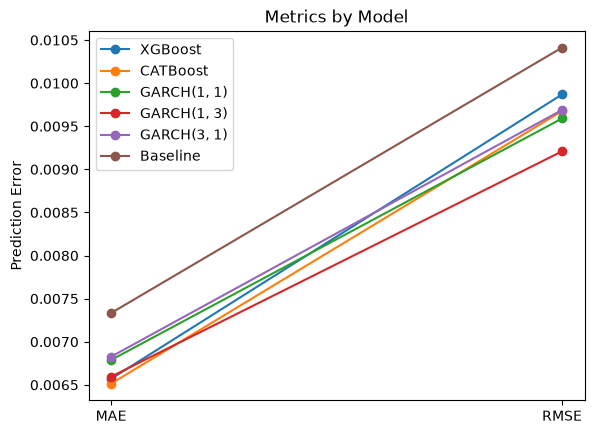

In [59]:
ax = models_results[-1].plot(marker="o",
                     title="Metrics by Model",
                     ylabel="Prediction Error",
                    )
ax.set_xticks([0, 1], ["MAE", "RMSE"])

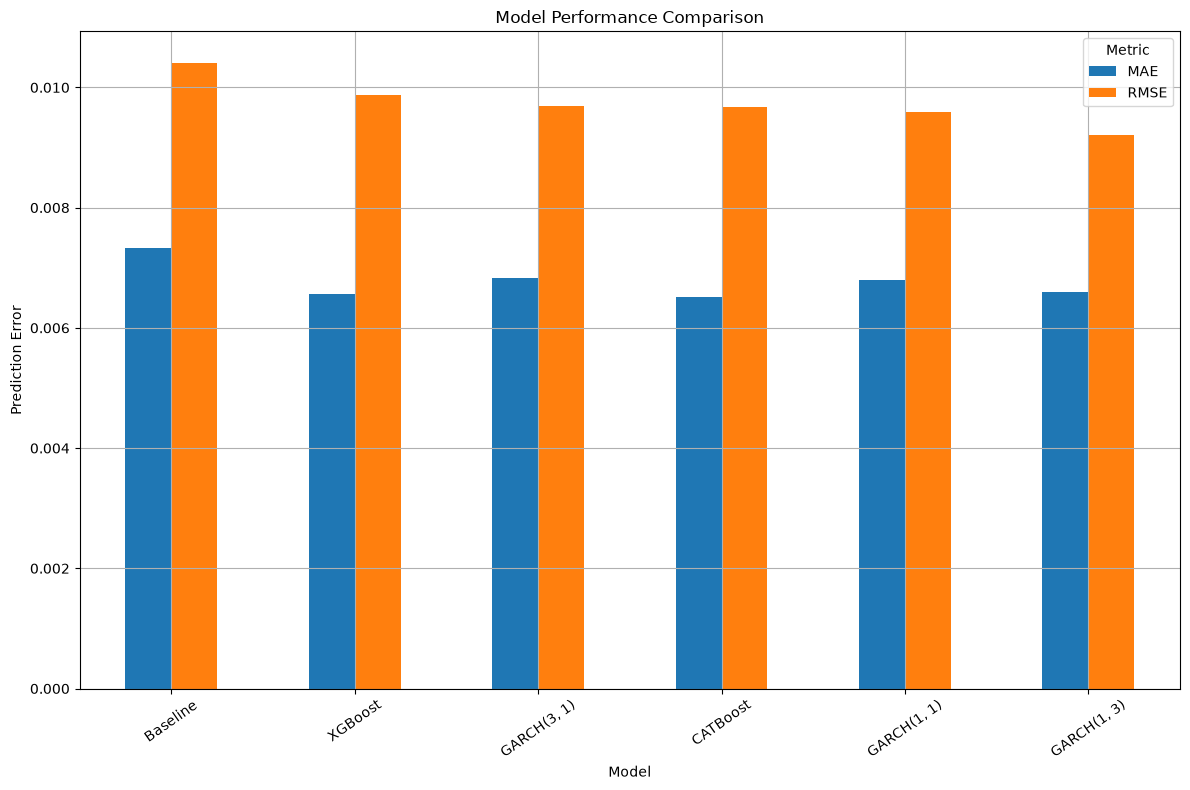

In [60]:
models_results[-1].T.sort_values(by=["RMSE", "MAE"], ascending=False).plot(kind="bar", figsize=(12, 8), rot=35)

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Prediction Error")
plt.legend(title="Metric")
plt.tight_layout()
plt.grid(True)
plt.show()

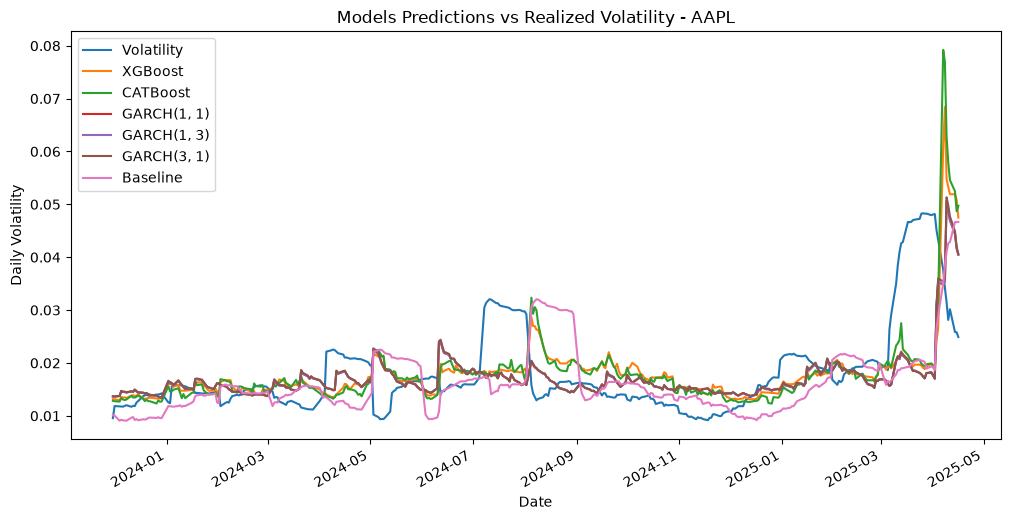

In [61]:
# Plot APPL results 
models_results[0][
    models_results[0]["Ticker"] == "AAPL"
].set_index("Date")[
    models_results[0].columns[2:].to_list()
].plot(figsize=(12, 6))

plt.title("Models Predictions vs Realized Volatility - AAPL")
plt.xlabel("Date")
plt.ylabel("Daily Volatility")
plt.legend()
plt.show()

In [65]:
garch_model(df, test, p=1, q=3)

GARCH MAE: 0.005908177746095186
GARCH RMSE: 0.008130387183066043


,Date,Ticker,Volatility,"GARCH(1, 3)"
0,2025-05-16,AAPL,0.017694,0.022597
1,2025-05-19,AAPL,0.017014,0.021921
2,2025-05-20,AAPL,0.016907,0.021243
3,2025-05-21,AAPL,0.016713,0.021309
4,2025-05-22,AAPL,0.016723,0.020506
...,...,...,...,...
10945,2026-10-22,XOM,0.018198,0.014172
10946,2026-10-23,XOM,0.018064,0.015488
10947,2026-10-26,XOM,0.018306,0.015042
10948,2026-10-27,XOM,0.018189,0.016106
